Install all necessary libraries:

In [1]:
%pip install keras
%pip install tensorflow
%pip install numpy
%pip install scikit-learn
%pip install pandas


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [31]:
# test harness for evaluating models on the cifar10 dataset
import sys
from matplotlib import pyplot
from keras.datasets import cifar10
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import Dense
from keras.layers import Flatten
from keras.optimizers import SGD
import tensorflow as tf
from tensorflow.keras import datasets
import matplotlib.pyplot as plt

Load the data from the CIFAR10 daatset and plot the images to evaluate the dataset:

In [32]:
# load dataset
(trainX, trainY), (testX, testY) = cifar10.load_data()

In [33]:

# one hot encode target values
trainY = to_categorical(trainY)
testY = to_categorical(testY)

Train: X=(50000, 32, 32, 3), y=(50000, 1)
Test: X=(10000, 32, 32, 3), y=(10000, 1)


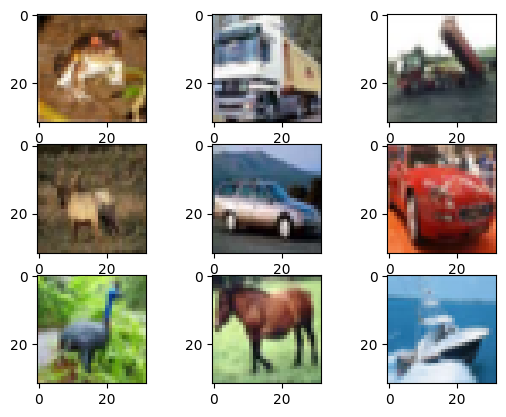

In [34]:
from matplotlib import pyplot
from keras.datasets import cifar10

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# example of loading the cifar10 dataset
from matplotlib import pyplot
from keras.datasets import cifar10
# load dataset
(trainX, trainy), (testX, testy) = cifar10.load_data()
# summarize loaded dataset
print('Train: X=%s, y=%s' % (trainX.shape, trainy.shape))
print('Test: X=%s, y=%s' % (testX.shape, testy.shape))
# plot first few images
for i in range(9):
	# define subplot
	pyplot.subplot(330 + 1 + i)
	# plot raw pixel data
	pyplot.imshow(trainX[i])
# show the figure
pyplot.show()

Load and test the dataset. 
Transform the integer into a 10 element binary vector with a 1 for the index of the class value. 
We can achieve this with the to_categorical() utility function.

In [35]:
# load train and test dataset
def load_dataset():
	# load dataset
	(trainX, trainY), (testX, testY) = cifar10.load_data()
	# one hot encode target values
	trainY = to_categorical(trainY)
	testY = to_categorical(testY)
	return trainX, trainY, testX, testY

In [36]:
print(trainY.shape)

(50000, 10)


The pixel values for each image in the dataset are unsigned integers in the range between no color and full color, or 0 and 255.
We need to rescale the pixel values from unsigned integers to floats and didvide the pixel values by the max value (255):

In [37]:
# scale pixels
def prep_pixels(train, test):
	# convert from integers to floats
	train_norm = train.astype('float32')
	test_norm = test.astype('float32')
	# normalize to range 0-1
	train_norm = train_norm / 255.0
	test_norm = test_norm / 255.0
	# return normalized images
	return train_norm, test_norm

In [ ]:
Define the model (this is the function to be filled-in or replaced later for a particular configuration to evaluate later on):

In [50]:
# define cnn model
def define_model():
	model = Sequential()
	model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
	model.add(layers.MaxPooling2D((2, 2)))
	model.add(layers.Conv2D(64, (3, 3), activation='relu'))
	model.add(layers.MaxPooling2D((2, 2)))
	model.add(layers.Conv2D(64, (3, 3), activation='relu'))
	model.add(layers.Flatten())
	model.add(layers.Dense(64, activation='relu'))
	model.add(layers.Dense(10))
	# compile model
	opt = SGD(learning_rate=0.001, momentum=0.9)
	model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
	return model

Evaluate the model: 

We need to specify the number of epochs and batch size. 
We will also divide the dataset into training, test nad validation sets.

In [51]:
# Slice notation
x_val = trainX[:10000] # Grab from 0 -> 10000
y_val = trainy[:10000]

y_val = to_categorical(y_val)


trainX_rest = trainX[10000:] # From 10000 -> end
trainy_rest = trainy[10000:]

print(x_val.shape)
print(y_val.shape)


(10000, 32, 32, 3)
(10000, 10)


In [52]:
# plot diagnostic learning curves
def summarize_diagnostics(history):
	# plot loss
	pyplot.subplot(211)
	pyplot.title('Cross Entropy Loss')
	pyplot.plot(history.history['loss'], color='blue', label='train')
	pyplot.plot(history.history['val_loss'], color='orange', label='test')
	# plot accuracy
	pyplot.subplot(212)
	pyplot.title('Classification Accuracy')
	pyplot.plot(history.history['accuracy'], color='blue', label='train')
	pyplot.plot(history.history['val_accuracy'], color='orange', label='test')
	# save plot to file
	filename = sys.argv[0].split('/')[-1]
	pyplot.savefig(filename + '_plot.png')
	pyplot.close()

Running the test harness for evaluation:

In [55]:
# run the test harness for evaluating a model
def run_test_harness():
	# load dataset
	trainX_rest, trainy_rest, testX, testy = load_dataset()
	# prepare pixel data
	trainX_rest, testX = prep_pixels(trainX_rest, testX)
	# define model
	model = define_model()
	# fit model
	history = model.fit(trainX_rest, trainy_rest, epochs=10,  validation_data=(x_val, y_val), verbose=0)
	# evaluate model
	_, acc = model.evaluate(testX, testy, verbose=0)
	print('> %.3f' % (acc * 100.0))
	# learning curves
	summarize_diagnostics(history)
 
# entry point, run the test harness
run_test_harness()



> 10.000


Model Baseline to establish minimum performance of a model - this will allow to compare all other models later on.

We will use the priciples of the VGG model as a starting point as they are easy to understand and performed very well in the 2014 competition.
The architecture is formed by blocks that are built from stacks of convolutional layers and small 3 by 3 filters followed by max pooling layer. 
These blockes can be repeated and the number of filters increased together with the network depth (32, 64, 128, 256) for the first four blocks of the model. Padding needs to be also used in the convolutional layers so the height and the width of the feature maps matches the input.

We will try this model on the CIFAR10 set and compare two models built of 1 and 2 blocks.

The layers will use the ReLU activation function and the "HE" weight initialisation. 

Baseline 1 VGG Block:

In [43]:
# define cnn model
def define_model():
	model = Sequential()
	model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
	model.add(layers.MaxPooling2D((2, 2)))
	model.add(layers.Conv2D(64, (3, 3), activation='relu'))
	model.add(layers.MaxPooling2D((2, 2)))
	model.add(layers.Conv2D(64, (3, 3), activation='relu'))
	return model